# Case 2: Beat the dumbest model

**Applies chapters 3 and 5:** the baseline, and logistic regression read as probability, direction and strength. It starts from case 1's state: the same 13 columns, the same seed-42 split, the test slice still sealed.

Kavya Nair, Kalpa's senior analyst, set the condition for the whole week: "Before you show me any model, show me the dumbest possible baseline and what beating it would prove." The bank's campaign manager is owed the same courtesy.

By the end of this notebook you can:

- score the majority-class baseline by hand and by code and get the same number;
- fit the logistic model on the customer table and say how far it sits above the baseline, in rows;
- read one coefficient in words a marketing manager can repeat;
- name the caveat that comes with a random split on this file.

**Search terms:** baseline model, majority class classifier, DummyClassifier, logistic regression coefficients, odds ratio.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

In [2]:
# Load the day's public dataset once; later runs read the cached copy.
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(bank.shape)

(41188, 21)


In [3]:
# The week's pipeline: the same columns, the same split and the same model every day.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLUMNS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

train, val, test = week_split(bank, seed=42)
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)
print(f"train {len(train):,}  validation {len(val):,}  test {len(test):,} (sealed)")

train 24,712  validation 8,238  test 8,238 (sealed)


## What does doing nothing score?

The dumbest model ignores every column and says the majority answer for everyone. Here the majority answer is no, so the model says "do not call" to all 8,238 validation clients and is right whenever the client would have said no anyway.

**Predict before you run.** What accuracy does "call nobody" score on validation? (a) 0.50 (b) 0.75 (c) 0.887 (d) 1.00

In [4]:
# The baseline twice: by hand from the share of no, then with scikit-learn's DummyClassifier.
from sklearn.dummy import DummyClassifier
by_hand = (y_val == 0).mean()
dummy = DummyClassifier(strategy="most_frequent").fit(train[COLUMNS], y_train)
by_code = accuracy_score(y_val, dummy.predict(val[COLUMNS]))
print(f"by hand: {(y_val == 0).sum():,} of {len(y_val):,} are no, accuracy {by_hand:.4f}")
print(f"by code: DummyClassifier accuracy {by_code:.4f}")
check("the hand count and DummyClassifier agree", abs(by_hand - by_code) < 1e-12)

by hand: 7,310 of 8,238 are no, accuracy 0.8874
by code: DummyClassifier accuracy 0.8874
PASS  the hand count and DummyClassifier agree


**What happened.** The answer is (c): calling nobody is right 7,310 times in 8,238, an accuracy of 0.8874. Any model that scores 0.88 has learned nothing, however good 88 sounds.

## Does the logistic model beat it?

The logistic model turns the 13 columns into a probability of yes for each client. Reading it as a yes when the probability is 0.5 or more gives a yes-or-no answer we can score with the same accuracy.

**Predict before you run.** How many more validation clients will the model get right than "call nobody" does? (a) about 800 (b) about 80 (c) about 8 (d) none

In [5]:
# Fit on train, score on validation. The test slice is not touched.
model = logistic(COLUMNS, bank).fit(train[COLUMNS], y_train)
p_val = model.predict_proba(val[COLUMNS])[:, 1]
pred = (p_val >= 0.5).astype(int)
acc = accuracy_score(y_val, pred)
right_model = int((pred == y_val).sum())
right_base = int((y_val == 0).sum())
print(f"logistic accuracy {acc:.4f}: {right_model:,} right of {len(y_val):,}")
print(f"baseline accuracy {by_hand:.4f}: {right_base:,} right of {len(y_val):,}")
print(f"edge: {right_model - right_base} more right answers, {100 * (acc - by_hand):.2f} points of accuracy")
check("the model beats the baseline on validation", acc > by_hand)
check("the edge is under two points", acc - by_hand < 0.02)

logistic accuracy 0.8971: 7,390 right of 8,238
baseline accuracy 0.8874: 7,310 right of 8,238
edge: 80 more right answers, 0.97 points of accuracy
PASS  the model beats the baseline on validation
PASS  the edge is under two points


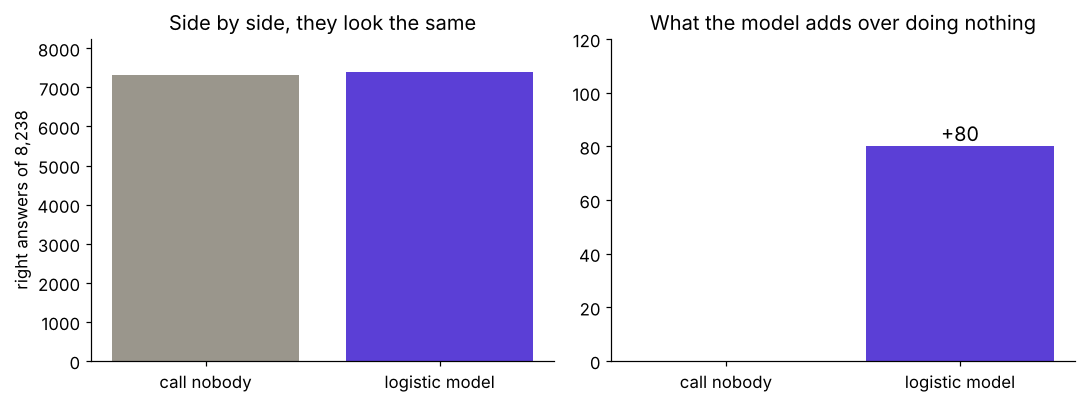

In [6]:
# The edge, drawn honestly: the full height first, then the gap that matters.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.bar(["call nobody", "logistic model"], [right_base, right_model], color=["#9A968C", "#5B3FD6"])
a1.set_ylim(0, len(y_val)); a1.set_ylabel("right answers of 8,238")
a1.set_title("Side by side, they look the same")
a2.bar(["call nobody", "logistic model"], [0, right_model - right_base], color=["#9A968C", "#5B3FD6"])
a2.text(1, right_model - right_base + 2, f"+{right_model - right_base}", ha="center", fontsize=13)
a2.set_ylim(0, 120); a2.set_title("What the model adds over doing nothing")
plt.tight_layout(); plt.show()

**What happened.** The answer is (b): 80 more right answers in 8,238, under one point of accuracy. The model does carry signal, and it is small. Tuesday asks how many of the 928 clients who said yes this model actually put on the call list, and that count changes how the 0.897 reads.

## What does one coefficient say to the campaign manager?

The logistic model's output for each client is a probability between 0 and 1. Its mean over validation should sit close to the share of yes, since the model is calibrated to this world.

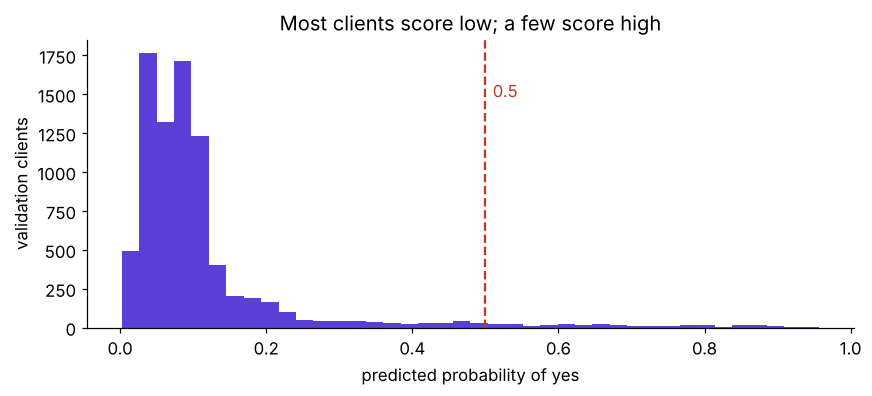

mean predicted probability 0.1140, share of yes 0.1126
PASS  the mean probability is within one point of the share of yes


In [7]:
# The model's probabilities: spread out, low on average, centred near the base rate.
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(p_val, bins=40, color="#5B3FD6")
ax.axvline(0.5, color="#C0392B", ls="--"); ax.text(0.51, ax.get_ylim()[1] * 0.8, "0.5", color="#C0392B")
ax.set_xlabel("predicted probability of yes"); ax.set_ylabel("validation clients")
ax.set_title("Most clients score low; a few score high")
plt.show()
print(f"mean predicted probability {p_val.mean():.4f}, share of yes {y_val.mean():.4f}")
check("the mean probability is within one point of the share of yes", abs(p_val.mean() - y_val.mean()) < 0.01)

`campaign` counts the calls already made to this client in the current campaign, including this one. The model stores its coefficient on the standardised scale, so divide by the column's spread to get it per call, then take `exp` to turn log-odds into a multiplier on the odds.

**Predict before you run.** One more call to the same client in this campaign does what to the odds of a yes? (a) doubles them (b) leaves them unchanged (c) lowers them a little (d) halves them

In [8]:
# Read the campaign coefficient per call, as a multiplier on the odds.
names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model.named_steps["model"].coef_[0], index=names)
scale = dict(zip(model.named_steps["prep"].named_transformers_["num"].feature_names_in_,
                 model.named_steps["prep"].named_transformers_["num"].scale_))
per_call = coefs["num__campaign"] / scale["campaign"]
print(f"log-odds per extra call {per_call:.4f}; odds multiplier {np.exp(per_call):.3f}")
print(f"in words: each extra call in this campaign goes with about {100 * (1 - np.exp(per_call)):.0f} percent lower odds of a yes, other columns held")

# A second route: add one call to every validation client and compare the odds directly.
bumped = val[COLUMNS].copy(); bumped["campaign"] += 1
p_bump = model.predict_proba(bumped)[:, 1]
ratio = (p_bump / (1 - p_bump)) / (p_val / (1 - p_val))
print(f"odds ratio measured on 8,238 clients: min {ratio.min():.4f}, max {ratio.max():.4f}")
check("the direction is negative", per_call < 0)
check("the measured odds ratio equals exp(coefficient) for every client", np.allclose(ratio, np.exp(per_call)))

log-odds per extra call -0.0690; odds multiplier 0.933
in words: each extra call in this campaign goes with about 7 percent lower odds of a yes, other columns held
odds ratio measured on 8,238 clients: min 0.9334, max 0.9334
PASS  the direction is negative
PASS  the measured odds ratio equals exp(coefficient) for every client


**What happened.** The answer is (c). Direction: negative, so more calls go with fewer yeses. Strength: each extra call multiplies the odds by 0.93, about 7 percent lower. For the campaign manager: "Calling the same client again and again is associated with a falling chance of a yes, about 7 percent lower odds per call, other things equal." That is an association inside this fit. Whether the extra calls cause the fall needs an experiment, which Week 1 Thursday taught.

## What caveat travels with this score?

The file is sorted by date from May 2008 to November 2010, and our random split mixes those years. If the share of yes changed a lot from year to year, the `month` column helps the model guess the period, and some of the 80 extra right answers are the calendar talking.

       rows  yes_share
year                  
2008  27690      0.048
2009  11440      0.195
2010   2058      0.521


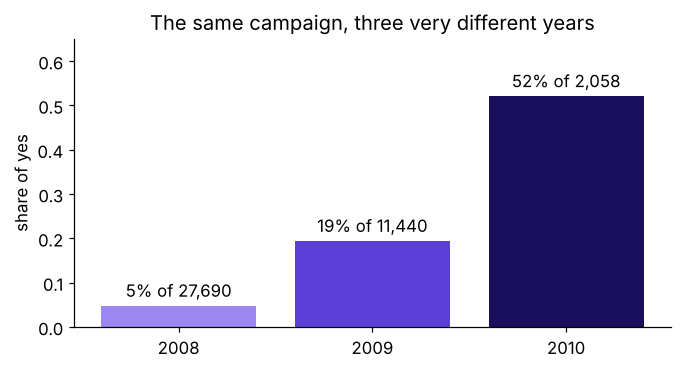

PASS  the three years cover every row


In [9]:
# Recover the year from row order (the month index drops when a new year starts) and count yes by year.
order = {m: i for i, m in enumerate(["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"])}
year, prev, years = 2008, -1, []
for m in bank["month"]:
    if order[m] < prev:
        year += 1
    prev = order[m]; years.append(year)
by_year = bank.assign(year=years).groupby("year")["y"].agg(rows="size", yes_share=lambda s: (s == "yes").mean())
print(by_year.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(by_year.index.astype(str), by_year["yes_share"], color=["#9C88F0", "#5B3FD6", "#1A0F5C"])
for x, (n, s) in enumerate(zip(by_year["rows"], by_year["yes_share"])):
    ax.text(x, s + 0.02, f"{s:.0%} of {n:,}", ha="center")
ax.set_ylim(0, 0.65); ax.set_ylabel("share of yes"); ax.set_title("The same campaign, three very different years")
plt.show()
check("the three years cover every row", by_year["rows"].sum() == len(bank))

**The caveat, in one line for the memo:** on a random split this score is partly about when the call was made, because the share of yes rose from 5 percent in 2008 to 52 percent in 2010. Friday splits by time instead and shows what that does.

## The trap: quoting 0.897 on its own

A hurried status update reads: "Our model is 89.7 percent accurate." The number is right and the sentence misleads, because doing nothing scores 88.7. Written with its baseline, it reads: "The model beats calling nobody by under one point, 80 more right answers in 8,238; Tuesday checks whether those are the clients we want." The first sentence gets a model shipped; the second gets the right question asked.

## What did this notebook establish?

| Question | Answer |
|---|---|
| What does doing nothing score? | 0.8874 on validation, 7,310 right of 8,238 |
| What does the logistic model score? | 0.8971, 7,390 right: 80 more, under one point |
| What does the model output? | a probability per client, mean 0.114 against a share of yes of 0.113 |
| One coefficient for the campaign manager | each extra call goes with about 7 percent lower odds of a yes, other columns held |
| The caveat | the random split mixes 2008 (5 percent yes) with 2010 (52 percent), so part of the score is the calendar |

**Next:** case 3 shows the fastest way to make 0.897 look better than it is, and why the envelope stays on the wall.